En el estudio de la empresa WoodCorp se indentifican muchos posibles puntos a analizar que podrian ser relevantes para poder entender el porque las metricas no se cumplen en el margen propuesto.
Observemos primero el contexto:

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# 1. Leer el dataset
df = pd.read_csv("Woodcorp O2C Case Table.csv")

# 2. Corregir tipos de datos numéricos (cambiar la coma por punto y convertir a float)
df['ORDER_VALUE'] = df['ORDER_VALUE'].str.replace(',', '.').astype(float)
df['UNIT_PRICE'] = df['UNIT_PRICE'].str.replace(',', '.').astype(float)

# 3. Convertir fechas a formato datetime
df['PROMISED_DATE'] = pd.to_datetime(df['PROMISED_DATE'])
df['DELIVERED_DATE'] = pd.to_datetime(df['DELIVERED_DATE'])

# 4. Limpiar espacios iniciales/finales en la variable de país
df['CUST_COUNTRY'] = df['CUST_COUNTRY'].str.strip()

# (Opcional) Verificar que los tipos hayan cambiado correctamente
print(df.dtypes)

CASE_KEY                                     int64
DELIVERY_COMPANY                               str
PRODUCT_TYPE                                   str
FACTORY                                        str
ORDERED_QUANTITY                             int64
DELIVERED_QUANTITY                           int64
MIN_ORDER_TOLERANCE                          int64
MAX_ORDER_TOLERANCE                          int64
CUST_MARKET                                    str
CUST_ID                                      int64
CUST_NAME                                      str
CUST_ADDR_CODE                               int64
DAYS_TO_DEL_DEADLINE                         int64
ORDER_TOLERANCE_MET                          int64
ORDER_DATE_MET                               int64
X_CEL_O2C_CASES.SAL_ORD_POS_QUAN             int64
DELIVERED_QUANTITY_UNIT                        str
WAREHOUSE_TYPE                                 str
DELIVERED_DATE                      datetime64[us]
PROMISED_DATE                  

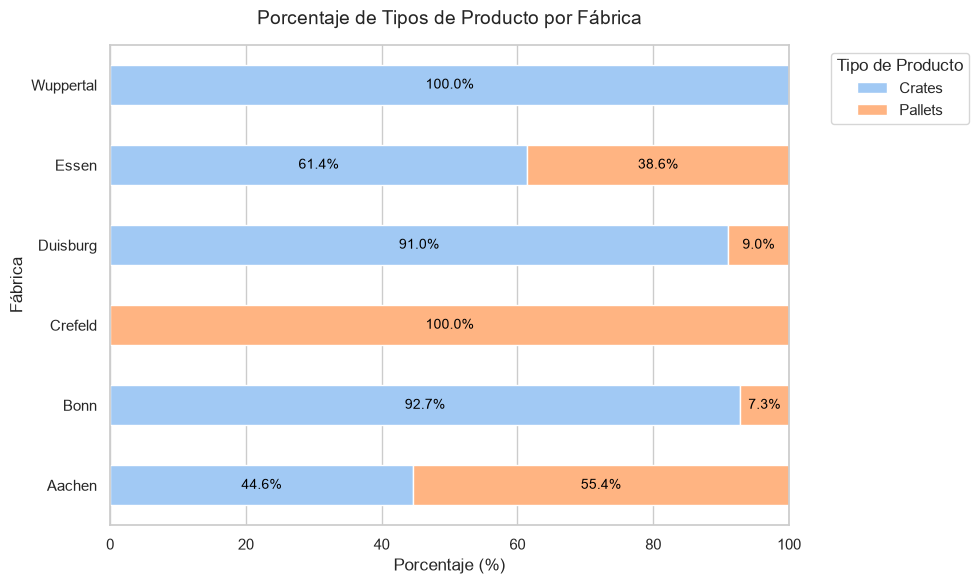

In [4]:
# Calcular la proporción de tipos de producto por fábrica en porcentajes
prod_por_fabrica = pd.crosstab(df['FACTORY'], df['PRODUCT_TYPE'], normalize='index') * 100

# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras apiladas horizontales
fig, ax = plt.subplots(figsize=(10, 6))
prod_por_fabrica.plot(kind='barh', stacked=True, color=['#a1c9f4', '#ffb482'], ax=ax)

# Personalizar etiquetas y títulos
ax.set_title('Porcentaje de Tipos de Producto por Fábrica', fontsize=14, pad=15)
ax.set_xlabel('Porcentaje (%)', fontsize=12)
ax.set_ylabel('Fábrica', fontsize=12)
ax.legend(title='Tipo de Producto', bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir las etiquetas de porcentaje dentro de las barras
for c in ax.containers:
    labels = [f'{w:.1f}%' if w > 0 else '' for w in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

In [5]:
# Convertir las columnas a formato de fecha (datetime)
df['PROMISED_DATE'] = pd.to_datetime(df['PROMISED_DATE'])
df['DELIVERED_DATE'] = pd.to_datetime(df['DELIVERED_DATE'])

# Calcular y mostrar los rangos
rango_prometido_inicio = df['PROMISED_DATE'].min()
rango_prometido_fin = df['PROMISED_DATE'].max()

rango_entregado_inicio = df['DELIVERED_DATE'].min()
rango_entregado_fin = df['DELIVERED_DATE'].max()

print(f"PROMISED_DATE: de {rango_prometido_inicio} a {rango_prometido_fin}")
print(f"DELIVERED_DATE: de {rango_entregado_inicio} a {rango_entregado_fin}")

PROMISED_DATE: de 2018-01-02 00:00:01 a 2019-11-13 00:00:01
DELIVERED_DATE: de 2017-11-22 00:00:01 a 2019-12-31 00:00:01


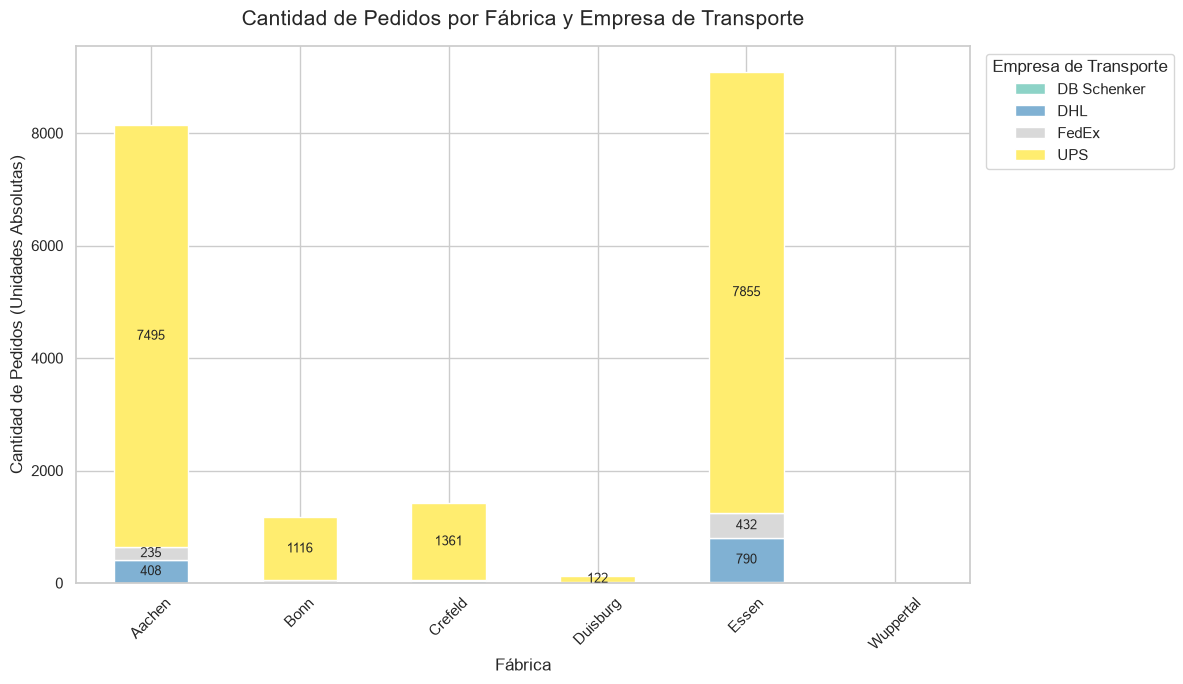

In [6]:
# 2. Crear una tabla cruzada con la cantidad absoluta de pedidos
pedidos_fab_trans = pd.crosstab(df['FACTORY'], df['DELIVERY_COMPANY'])

# 3. Configurar estilo visual
sns.set_theme(style="whitegrid")

# 4. Crear el gráfico de barras apiladas
fig, ax = plt.subplots(figsize=(12, 7))
pedidos_fab_trans.plot(kind='bar', stacked=True, colormap='Set3', ax=ax)

# 5. Personalizar etiquetas, leyenda y títulos
ax.set_title('Cantidad de Pedidos por Fábrica y Empresa de Transporte', fontsize=15, pad=15)
ax.set_xlabel('Fábrica', fontsize=12)
ax.set_ylabel('Cantidad de Pedidos (Unidades Absolutas)', fontsize=12)
ax.legend(title='Empresa de Transporte', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=45)

# 6. Añadir los números dentro de las barras (omitiendo valores muy pequeños para mayor limpieza)
for c in ax.containers:
    labels = [f'{int(w)}' if w > 100 else '' for w in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', fontsize=9)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

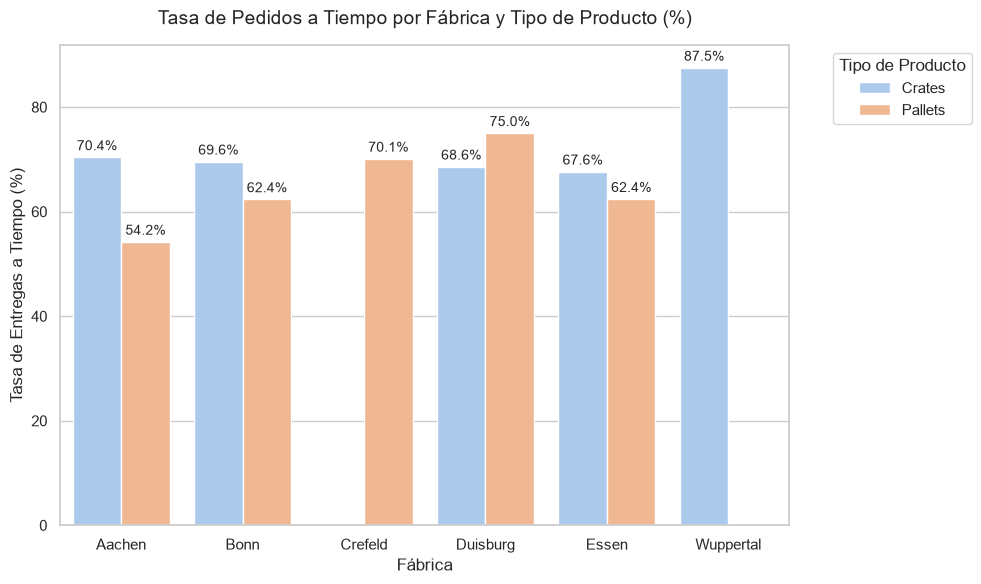

In [7]:
# 1. Cargar datos
df = pd.read_csv('Woodcorp O2C Case Table.csv')

# 2. Calcular la tasa de pedidos a tiempo (ORDER_DATE_MET = 1 si llegó a tiempo)
ontime_rate = df.groupby(['FACTORY', 'PRODUCT_TYPE'])['ORDER_DATE_MET'].mean().reset_index()
ontime_rate['ORDER_DATE_MET'] = ontime_rate['ORDER_DATE_MET'] * 100  # A porcentaje

# 3. Configurar gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear gráfico de barras agrupado por producto
ax = sns.barplot(
    data=ontime_rate, 
    x='FACTORY', 
    y='ORDER_DATE_MET', 
    hue='PRODUCT_TYPE', 
    palette=['#a1c9f4', '#ffb482']
)

# 4. Formato
plt.title('Tasa de Pedidos a Tiempo por Fábrica y Tipo de Producto (%)', fontsize=14, pad=15)
plt.xlabel('Fábrica', fontsize=12)
plt.ylabel('Tasa de Entregas a Tiempo (%)', fontsize=12)
plt.legend(title='Tipo de Producto', bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir etiquetas de porcentaje
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=3, fontsize=10)

plt.tight_layout()
plt.show()